# 🏃📊 Tracking data (ATD)

The **Automatic Tracking Data**: computer-vision output giving the position and speed of every
tracked object on the pitch, once per video frame, **including the ball**.

This notebook covers loading it, how it lines up with the frames you label, what it does not
contain, and how to look at it.

---

## Loading

The ATD is Metrica's **FIFA/EPTS** export — a metadata XML plus a raw text file — so
[kloppy](https://kloppy.pysport.org/user-guide/loading-data/metrica/) reads the pair directly.

The match was recorded twice. This is the **tactical** recording, the one a submission is
indexed to; `source='broadcast'` gets the other, on its own timeline.

In [ ]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import matplotlib.pyplot as plt
from kloppy import metrica

import games

paths = games.asset_paths(source='tactical')

# The full file is 199,319 frames. Enough here to reach the first-half kickoff at 11185.
dataset = metrica.load_tracking_epts(meta_data=paths['atd_meta'],
                                     raw_data=paths['atd_raw'], limit=12000)
print('%d frames loaded' % len(dataset.records))


12000 frames loaded


In [4]:
df = dataset.to_df()

print("Total rows:", len(df))
print("Total columns:", len(df.columns))

print("\nAll columns:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")



Total rows: 12000
Total columns: 193

All columns:
1. period_id
2. timestamp
3. frame_id
4. ball_state
5. ball_owning_team_id
6. ball_x
7. ball_y
8. ball_z
9. ball_speed
10. 1_x
11. 1_y
12. 1_d
13. 1_s
14. 2_x
15. 2_y
16. 2_d
17. 2_s
18. 3_x
19. 3_y
20. 3_d
21. 3_s
22. 4_x
23. 4_y
24. 4_d
25. 4_s
26. 5_x
27. 5_y
28. 5_d
29. 5_s
30. 6_x
31. 6_y
32. 6_d
33. 6_s
34. 7_x
35. 7_y
36. 7_d
37. 7_s
38. 8_x
39. 8_y
40. 8_d
41. 8_s
42. 9_x
43. 9_y
44. 9_d
45. 9_s
46. 10_x
47. 10_y
48. 10_d
49. 10_s
50. 11_x
51. 11_y
52. 11_d
53. 11_s
54. 12_x
55. 12_y
56. 12_d
57. 12_s
58. 13_x
59. 13_y
60. 13_d
61. 13_s
62. 14_x
63. 14_y
64. 14_d
65. 14_s
66. 15_x
67. 15_y
68. 15_d
69. 15_s
70. 16_x
71. 16_y
72. 16_d
73. 16_s
74. 17_x
75. 17_y
76. 17_d
77. 17_s
78. 18_x
79. 18_y
80. 18_d
81. 18_s
82. 19_x
83. 19_y
84. 19_d
85. 19_s
86. 20_x
87. 20_y
88. 20_d
89. 20_s
90. 21_x
91. 21_y
92. 21_d
93. 21_s
94. 22_x
95. 22_y
96. 22_d
97. 22_s
98. 23_x
99. 23_y
100. 23_d
101. 23_s
102. 24_x
103. 24_y
104. 24_d
105. 2

In [8]:
# Missing values per column
missing = df.isna().sum()

print("Total missing values:", missing.sum())
print("\nColumns with missing values:")
print(missing[missing > 0].sort_values(ascending=False).to_string())

Total missing values: 1840642

Columns with missing values:
ball_state             12000
ball_owning_team_id    12000
ball_speed             12000
ball_z                 12000
1_d                    12000
2_d                    12000
4_d                    12000
5_d                    12000
3_d                    12000
6_d                    12000
10_d                   12000
11_d                   12000
13_d                   12000
12_d                   12000
8_d                    12000
9_d                    12000
7_d                    12000
44_d                   12000
45_d                   12000
46_d                   12000
44_x                   12000
43_d                   12000
40_d                   12000
41_d                   12000
39_d                   12000
38_d                   12000
30_d                   12000
31_d                   12000
33_d                   12000
32_d                   12000
36_d                   12000
37_d                   12000
35_d        

## The data as a table

Each row is one video frame:

- **frame_id** — the tracking's own counter, starting at **1**
- **ball_x**, **ball_y** — the ball, when it is visible
- **1_x**, **1_y**, **1_s** — position and speed (m/s) of track slot 1, and so on

All positions are **normalised to 0–1**, not metres. At 25 fps, 25 rows is one second.

In [3]:
frame_df = dataset.to_df()
frame_df.head()

,period_id,timestamp,frame_id,ball_state,ball_owning_team_id,ball_x,ball_y,ball_z,ball_speed,1_x,...,44_d,44_s,45_x,45_y,45_d,45_s,46_x,46_y,46_d,46_s
0,1,0 days 00:00:00.040000,1,None,None,NaN,NaN,None,None,0.33411,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN
1,1,0 days 00:00:00.080000,2,None,None,NaN,NaN,None,None,0.33404,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN
2,1,0 days 00:00:00.120000,3,None,None,NaN,NaN,None,None,0.33396,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN
3,1,0 days 00:00:00.160000,4,None,None,NaN,NaN,None,None,0.33389,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN
4,1,0 days 00:00:00.200000,5,None,None,NaN,NaN,None,None,0.33382,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN


## Frame alignment — a single subtraction

The ATD counts from 1 and your submission counts from 0:

```
video_frame = frame_id - 1
```

That is the whole alignment story. `load_atd.check_alignment()` verifies it rather than
asserting it — the record count must equal the video length, and the ids must be exactly
`1..n` with nothing missing.

In [4]:
import load_atd

# Straight off the raw file -- one streaming pass, no kloppy. Loading all 199,319 frames through
# kloppy just to count them would cost minutes and gigabytes.
report = load_atd.check_alignment_raw()
for key, value in report.items():
    print('%-18s %s' % (key, value))

n_records          199319
n_video_frames     199319
frame_id_range     (1, 199319)
contiguous         True
first_video_frame  0
agrees             True


## What it does not contain

### No player identities

There are **46 track slots** for 22 players. They are named `Track 1`…`Track 46` and their
`ShirtNumber` is just the slot index — **not a shirt number, and not a person**. Slots start,
stop and swap identity as the tracker loses and re-acquires people.

You get positions and team membership. Any analysis you build has to be collective.

In [5]:
players = dataset.metadata.teams[0].players + dataset.metadata.teams[1].players
print('%d track slots' % len(players))
for player in players[:3]:
    print('  %-10s shirt %-3s team %s' % (player.name, player.jersey_no, player.team))
print('  ...')

46 track slots
  Track 1    shirt 1   team Barcelona
  Track 2    shirt 2   team Barcelona
  Track 3    shirt 3   team Barcelona
  ...


### The ball is missing 43% of the time

The ball is the most informative signal in the file and the least reliable one. Count it
yourself before building anything that assumes it is there.

In [6]:
ball = frame_df[['ball_x', 'ball_y']]
seen = ball.notna().all(axis=1)
print('ball present on %d of %d loaded frames (%.1f%%)' % (seen.sum(), len(seen),
                                                           100 * seen.mean()))
print()
print('over the whole match it is 56.9%. See DATA.md.')

ball present on 984 of 12000 loaded frames (8.2%)

over the whole match it is 56.9%. See DATA.md.


## Pitch dimensions

Positions are normalised, so multiply by the real pitch to get metres.

In [7]:
length = dataset.metadata.pitch_dimensions.pitch_length
width = dataset.metadata.pitch_dimensions.pitch_width
print('ATD metadata: %s x %s m' % (length, width))
print('games.py:     %s x %s m  (measured from the corrected tracking)'
      % games.GAMES[games.GAME]['pitch'])

ATD metadata: 105 x 68 m
games.py:     105.3 x 68.0 m  (measured from the corrected tracking)


## Looking at a frame

`starter/utils.py` draws a pitch and plots both teams **and the ball**. The kickoff of the
first half is video frame 11185, which is also the first frame the ground truth grades.

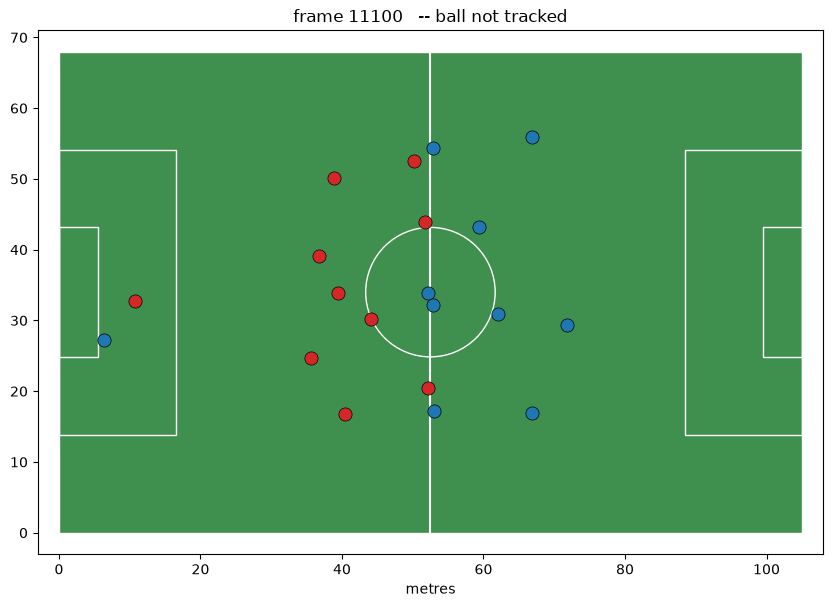

In [8]:
from utils import plot_frame

plot_frame(dataset, 11100)   # 1st half kickoff
plt.show()

Now a frame where the tracking has lost the ball. The title says so — there is no white dot,
and that is the data being honest rather than a plotting bug.

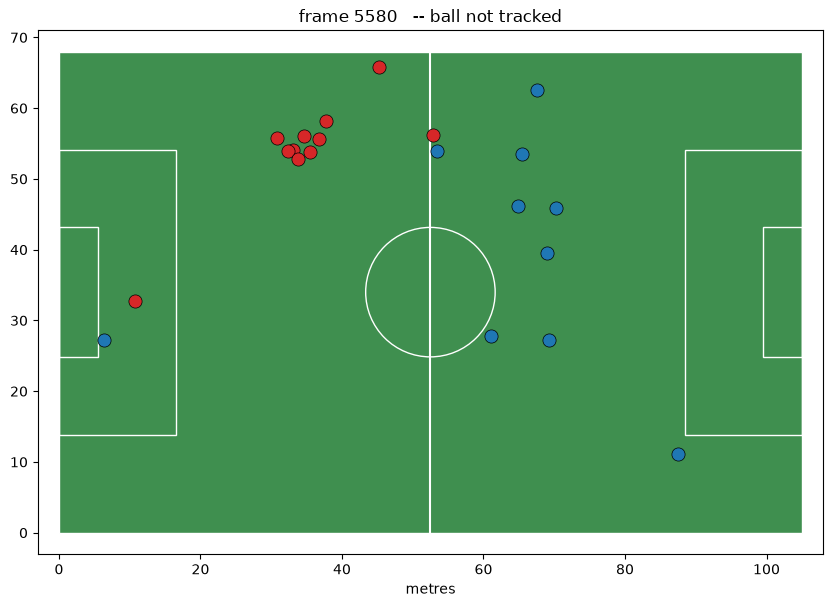

In [9]:
missing = int(np.flatnonzero(~seen.values)[len(np.flatnonzero(~seen.values)) // 2])
plot_frame(dataset, missing)
plt.show()

## Watching it move

A static frame hides the thing that actually tells you who has the ball: how the shape moves.

The ball simply disappears on frames where it was not tracked.

In [ ]:
from IPython.display import HTML
from utils import animate_frames

anim = animate_frames(dataset, 11145, 11535)   # 10 seconds from kickoff
HTML(anim.to_jshtml())

---

**Next:** [`03_first_submission.ipynb`](03_first_submission.ipynb) turns this into a scored
submission in one sitting.